# DQN — CartPole-v1
**Implementación, experimentos y resultados · Tier 1**

Este notebook explica la implementación de DQN y presenta sus resultados frente a Q-learning tabular. Las funciones son las mismas que `agents/dqn.py` y `experiments/train_dqn.py` del repositorio. **Las gráficas leen los resultados ya obtenidos en la carpeta `results/`**; los entrenamientos completos no se ejecutan automáticamente.

**Ruta de exposición:** red Q → replay buffer → epsilon-greedy → actualización TD → evaluación → entrenamiento → ajuste de hiperparámetros → resultados → comparación con Q-learning.

### Part 1 - Setup and Protocol
**¿Qué hicimos?** Usamos las mismas condiciones que Q-learning para que la comparación sea justa: CartPole-v1, 300.000 pasos por semilla, semillas 42, 123 y 456, evaluación cada 10.000 pasos con 10 episodios, y evaluación final de 100 episodios con epsilon = 0 (semillas 20000–20099). El objetivo es una recompensa media ≥ 475.

In [1]:
# ============================================================
# PART 1 - CONFIGURACIÓN
# ============================================================

import copy
import csv
import json
import time
from pathlib import Path

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

# Carpeta donde están los resultados de los entrenamientos.
# El notebook puede estar en la raíz del proyecto o en una subcarpeta.
RESULTS = Path("results") if Path("results").exists() else Path("../results")

SEMILLAS = [42, 123, 456]

# Protocolo común acordado con Q-learning
PROTOCOLO = {
    "eval_every": 10_000,           # evaluación periódica cada 10.000 pasos
    "eval_episodes": 10,            # ... con 10 episodios greedy
    "eval_seed_start": 10_000,      # semillas 10000-10009
    "final_eval_episodes": 100,     # evaluación final: 100 episodios
    "final_eval_seed_start": 20_000,  # semillas 20000-20099
}

# Hiperparámetros propios de DQN (configuración seleccionada, ver Part 8)
CONFIG_CARTPOLE = {
    "exp_name": "cartpole_dqn", "env_id": "CartPole-v1",
    "total_steps": 300_000, "success_threshold": 475, **PROTOCOLO,
    "gamma": 0.99, "lr": 1e-4, "batch_size": 128, "buffer_size": 100_000,
    "hidden": [128, 128], "learning_starts": 1_000, "train_freq": 1,
    "target_update_freq": 1_000, "eps_start": 1.0, "eps_end": 0.05,
    "exploration_fraction": 0.1, "max_grad_norm": 10.0, "double": False,
}

env = gym.make("CartPole-v1")
print("Observación:", env.observation_space.shape, "| Acciones:", env.action_space.n)
print("Límite de pasos por episodio:", env.spec.max_episode_steps)
print("Resultados en:", RESULTS.resolve())

Observación: (4,) | Acciones: 2
Límite de pasos por episodio: 500
Resultados en: /home/adriana/Documents/agentes_inteligentes/project/results


### Part 2 - Q-Network
**¿Qué implementamos?** En vez de una tabla, una red neuronal recibe los 4 valores continuos del estado y devuelve **un valor Q por acción** (izquierda y derecha). Así no hace falta discretizar: la red generaliza entre estados parecidos.

- **Arquitectura:** 4 → 128 → 128 → 2, con ReLU.
- **Ventaja:** sirve para estados continuos o muy grandes.
- **Riesgo:** cambiar los pesos para un estado cambia también los valores de todos los demás.

In [2]:
# ============================================================
# RED Q
# ============================================================

class QNetwork(nn.Module):
    """MLP que recibe el estado y devuelve un valor Q por cada acción."""

    def __init__(self, obs_dim, n_actions, hidden=(128, 128)):
        super().__init__()
        capas, entrada = [], obs_dim
        for h in hidden:
            capas += [nn.Linear(entrada, h), nn.ReLU()]
            entrada = h
        capas.append(nn.Linear(entrada, n_actions))   # una salida por acción
        self.net = nn.Sequential(*capas)

    def forward(self, x):
        return self.net(x)


# Comprobación: 5 estados de CartPole -> 5 x 2 valores Q
red = QNetwork(obs_dim=4, n_actions=2)
salida = red(torch.zeros(5, 4))
print("Forma de la salida:", tuple(salida.shape))
print("Parámetros entrenables:", sum(p.numel() for p in red.parameters()))
assert salida.shape == (5, 2)


Forma de la salida: (5, 2)
Parámetros entrenables: 17410


### Part 3 - Replay Buffer
**¿Para qué sirve?** Guarda las transiciones `(s, a, r, s', terminated)` y entrena con minibatches elegidos **al azar**. Si entrenáramos con pasos consecutivos, los datos estarían muy correlacionados y la red se ajustaría solo a lo más reciente. Además, cada transición se reutiliza muchas veces.

In [3]:
# ============================================================
# REPLAY BUFFER
# ============================================================

class ReplayBuffer:
    """Memoria circular: cuando se llena, sobrescribe lo más antiguo."""

    def __init__(self, capacity, obs_dim, rng):
        self.capacity, self.rng = capacity, rng
        self.obs = np.zeros((capacity, obs_dim), dtype=np.float32)
        self.next_obs = np.zeros((capacity, obs_dim), dtype=np.float32)
        self.actions = np.zeros(capacity, dtype=np.int64)
        self.rewards = np.zeros(capacity, dtype=np.float32)
        self.dones = np.zeros(capacity, dtype=np.float32)   # 1 solo si terminated
        self.pos, self.size = 0, 0

    def add(self, obs, action, reward, next_obs, terminated):
        i = self.pos
        self.obs[i], self.next_obs[i] = obs, next_obs
        self.actions[i], self.rewards[i] = action, reward
        self.dones[i] = float(terminated)
        self.pos = (self.pos + 1) % self.capacity
        self.size = min(self.size + 1, self.capacity)

    def sample(self, batch_size):
        # Muestreo uniforme: rompe la correlación entre pasos consecutivos
        idx = self.rng.integers(0, self.size, size=batch_size)
        return (torch.as_tensor(self.obs[idx]), torch.as_tensor(self.actions[idx]),
                torch.as_tensor(self.rewards[idx]), torch.as_tensor(self.next_obs[idx]),
                torch.as_tensor(self.dones[idx]))


# Comprobación con un buffer pequeño
buf = ReplayBuffer(capacity=3, obs_dim=4, rng=np.random.default_rng(0))
for k in range(5):                      # 5 transiciones en un buffer de 3
    buf.add(np.full(4, k), k % 2, 1.0, np.full(4, k + 1), terminated=(k == 4))
print("Tamaño:", buf.size, "| posiciones guardadas:", buf.obs[:, 0])
print("Se conservan las 3 transiciones más recientes (2, 3 y 4).")


Tamaño: 3 | posiciones guardadas: [3. 4. 2.]
Se conservan las 3 transiciones más recientes (2, 3 y 4).


### Part 4 - Epsilon-Greedy Exploration
**¿Cómo explora?** Con probabilidad epsilon elige una acción aleatoria; si no, la de mayor Q. Epsilon baja linealmente de 1.0 a 0.05 durante el primer 10 % del entrenamiento (30.000 pasos) y después se mantiene en 0.05.

In [4]:
# ============================================================
# EXPLORACIÓN EPSILON-GREEDY CON DECAIMIENTO LINEAL
# ============================================================

def linear_epsilon(step, eps_start, eps_end, decay_steps):
    """Baja linealmente de eps_start a eps_end y luego se mantiene constante."""
    frac = min(1.0, step / max(1, decay_steps))
    return eps_start + frac * (eps_end - eps_start)


for paso in [0, 15_000, 30_000, 100_000, 300_000]:
    print(f"Paso {paso:>7}: epsilon = {linear_epsilon(paso, 1.0, 0.05, 30_000):.3f}")


Paso       0: epsilon = 1.000
Paso   15000: epsilon = 0.525
Paso   30000: epsilon = 0.050
Paso  100000: epsilon = 0.050
Paso  300000: epsilon = 0.050


### Part 5 - DQN Agent and TD Update
**¿Cómo aprende?** Para cada transición calcula el objetivo TD con la **red objetivo**, una copia congelada que se actualiza cada 1.000 pasos:

$$y = r + \gamma\,(1 - d)\,\max_{a'} Q_{\text{objetivo}}(s', a')$$

y ajusta la red online para acercar $Q(s,a)$ a $y$ con la **Huber loss**, que es menos sensible a errores grandes que el error cuadrático.

- **Red objetivo:** si el objetivo se calculara con la misma red que se entrena, se movería en cada paso.
- **`d` solo vale 1 si el episodio terminó de verdad** (`terminated`). Si se cortó por llegar a 500 pasos (`truncated`), el estado siguiente sigue teniendo valor futuro.
- **Clip del gradiente (norma 10):** evita saltos bruscos de los pesos.

In [5]:
# ============================================================
# AGENTE DQN (incluye la opción Double DQN, usada en el Tier 3)
# ============================================================

class DQNAgent:
    def __init__(self, obs_dim, n_actions, cfg, rng):
        self.cfg, self.n_actions, self.rng = cfg, n_actions, rng
        self.gamma, self.batch_size = cfg["gamma"], cfg["batch_size"]
        self.double = cfg.get("double", False)

        self.q_net = QNetwork(obs_dim, n_actions, tuple(cfg["hidden"]))
        # Red objetivo: copia congelada que se sincroniza cada C pasos
        self.target_net = copy.deepcopy(self.q_net)
        self.target_net.requires_grad_(False)

        self.optimizer = torch.optim.Adam(self.q_net.parameters(), lr=cfg["lr"])
        self.buffer = ReplayBuffer(cfg["buffer_size"], obs_dim, rng)

    @torch.no_grad()
    def greedy_action(self, obs):
        q = self.q_net(torch.as_tensor(obs, dtype=torch.float32).unsqueeze(0))
        return int(q.argmax(dim=1).item())

    def act(self, obs, epsilon):
        if self.rng.random() < epsilon:             # explorar
            return int(self.rng.integers(self.n_actions))
        return self.greedy_action(obs)              # explotar

    @torch.no_grad()
    def max_q(self, obs):
        """max_a Q(s, a): lo que la red cree que vale el estado s."""
        q = self.q_net(torch.as_tensor(obs, dtype=torch.float32).unsqueeze(0))
        return float(q.max().item())

    def update(self):
        obs, actions, rewards, next_obs, dones = self.buffer.sample(self.batch_size)

        # Q(s, a) de las acciones que realmente se tomaron
        q_values = self.q_net(obs).gather(1, actions.unsqueeze(1)).squeeze(1)

        with torch.no_grad():
            if self.double:
                # Double DQN: la red ONLINE elige la acción, la red OBJETIVO la evalúa
                next_actions = self.q_net(next_obs).argmax(dim=1, keepdim=True)
                next_q = self.target_net(next_obs).gather(1, next_actions).squeeze(1)
            else:
                # DQN: la red objetivo elige y evalúa con el mismo max
                next_q = self.target_net(next_obs).max(dim=1).values
            # (1 - done) corta el bootstrap solo en estados terminales reales
            targets = rewards + self.gamma * (1.0 - dones) * next_q

        loss = F.smooth_l1_loss(q_values, targets)   # Huber loss
        self.optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(self.q_net.parameters(), self.cfg.get("max_grad_norm", 10.0))
        self.optimizer.step()
        return float(loss.item()), float(q_values.mean().item())

    def sync_target(self):
        self.target_net.load_state_dict(self.q_net.state_dict())


# Comprobación: una actualización con datos aleatorios
_cfg = {"gamma": 0.99, "batch_size": 8, "hidden": [16, 16], "lr": 1e-3, "buffer_size": 50}
_ag = DQNAgent(4, 2, _cfg, np.random.default_rng(0))
for _ in range(20):
    _ag.buffer.add(np.random.randn(4), np.random.randint(2), 1.0, np.random.randn(4), False)
print("Loss de una actualización: %.4f" % _ag.update()[0])


Loss de una actualización: 0.5630


### Part 6 - Evaluation Without Exploration
**¿Cómo evaluamos?** Con epsilon = 0 y sin entrenar. Además guardamos dos valores para el estado inicial $s_0$: lo que la red **estima** ($\max_a Q(s_0,a)$) y el retorno descontado **real** que obtuvo. Si el estimado queda por encima del real, la red sobreestima (se analiza en el Tier 3).

In [6]:
# ============================================================
# EVALUACIÓN GREEDY (EPSILON = 0)
# ============================================================

def evaluate(agent, env, seeds, gamma):
    """Un episodio greedy por semilla. También mide la sobreestimación de Q en s0."""
    returns, q0_est, q0_real = [], [], []
    for s in seeds:
        obs, _ = env.reset(seed=int(s))
        q0_est.append(agent.max_q(obs))          # lo que la red predice para s0
        done, ret, disc, factor = False, 0.0, 0.0, 1.0
        while not done:
            obs, r, terminated, truncated, _ = env.step(agent.greedy_action(obs))
            ret += r
            disc += factor * r                   # retorno descontado real desde s0
            factor *= gamma
            done = terminated or truncated
        returns.append(ret)
        q0_real.append(disc)
    return np.array(returns), np.array(q0_est), np.array(q0_real)


### Part 7 - Training by Steps
**¿Cómo se conectan las funciones?** En cada paso: elegir acción → ejecutarla → guardar la transición → actualizar la red → sincronizar la red objetivo cada 1.000 pasos → evaluar cada 10.000 pasos. El tiempo de entrenamiento **no incluye** las evaluaciones.

La función **no se ejecuta automáticamente**: un entrenamiento completo tarda unos 7 minutos por semilla. Para una demostración rápida en la defensa, cambia `DEMO = True`.

In [7]:
# ============================================================
# ENTRENAMIENTO POR PASOS (mismo código que experiments/train_dqn.py)
# ============================================================

def entrenar_dqn(cfg, seed, results_dir=RESULTS):
    out = Path(results_dir) / cfg["exp_name"] / f"seed_{seed}"
    out.mkdir(parents=True, exist_ok=True)

    torch.set_num_threads(1)
    np.random.seed(seed)
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)

    env, eval_env = gym.make(cfg["env_id"]), gym.make(cfg["env_id"])
    env.action_space.seed(seed)
    obs, _ = env.reset(seed=seed)
    agent = DQNAgent(env.observation_space.shape[0], env.action_space.n, cfg, rng)

    total = cfg["total_steps"]
    decay = int(cfg["exploration_fraction"] * total)
    eval_seeds = range(cfg["eval_seed_start"], cfg["eval_seed_start"] + cfg["eval_episodes"])
    final_seeds = range(cfg["final_eval_seed_start"],
                        cfg["final_eval_seed_start"] + cfg["final_eval_episodes"])

    filas, train_time, t0 = [], 0.0, time.perf_counter()
    steps_to_threshold = None
    for step in range(1, total + 1):
        eps = linear_epsilon(step, cfg["eps_start"], cfg["eps_end"], decay)
        action = agent.act(obs, eps)
        next_obs, r, terminated, truncated, _ = env.step(action)
        # Se guarda `terminated`, NO `truncated`: cortar por tiempo no es un fallo
        agent.buffer.add(obs, action, r, next_obs, terminated)
        obs = next_obs
        if terminated or truncated:
            obs, _ = env.reset()

        if step > cfg["learning_starts"] and step % cfg["train_freq"] == 0:
            agent.update()
        if step % cfg["target_update_freq"] == 0:
            agent.sync_target()

        if step % cfg["eval_every"] == 0:          # se pausa el cronómetro
            train_time += time.perf_counter() - t0
            ret, q0e, q0r = evaluate(agent, eval_env, eval_seeds, cfg["gamma"])
            filas.append([step, ret.mean(), ret.std(), eps, train_time, q0e.mean(), q0r.mean()])
            if steps_to_threshold is None and ret.mean() >= cfg["success_threshold"]:
                steps_to_threshold = step
            print(f"seed {seed} | paso {step:>7} | eval {ret.mean():7.2f} | eps {eps:.3f}")
            t0 = time.perf_counter()
    train_time += time.perf_counter() - t0

    pd.DataFrame(filas, columns=["step", "eval_mean", "eval_std", "epsilon", "train_time_s",
                                 "q0_estimate", "q0_actual"]).to_csv(out / "eval.csv", index=False)
    ret, q0e, q0r = evaluate(agent, eval_env, final_seeds, cfg["gamma"])
    resumen = {"seed": seed, "final_mean": float(ret.mean()), "final_std": float(ret.std()),
               "solved": bool(ret.mean() >= cfg["success_threshold"]),
               "steps_to_threshold": steps_to_threshold, "train_time_s": round(train_time, 2),
               "final_q0_estimate": float(q0e.mean()), "final_q0_actual": float(q0r.mean()),
               "final_returns": ret.tolist(), "best_ckpt_mean": float("nan")}
    json.dump(resumen, open(out / "final.json", "w"), indent=2)
    torch.save(agent.q_net.state_dict(), out / "model_final.pt")
    return resumen


In [8]:
# Demostración opcional (unos segundos). No sobrescribe los resultados reales.
DEMO = False

if DEMO:
    demo_cfg = {**CONFIG_CARTPOLE, "exp_name": "demo_cartpole", "total_steps": 20_000,
                "eval_every": 5_000, "final_eval_episodes": 10}
    print(entrenar_dqn(demo_cfg, seed=42, results_dir="/tmp/demo_results"))
else:
    print("Demostración desactivada. Entrenamiento completo: "
          "python -m experiments.run_seeds --config experiments/configs/cartpole_dqn.json")

Demostración desactivada. Entrenamiento completo: python -m experiments.run_seeds --config experiments/configs/cartpole_dqn.json


In [9]:
# ============================================================
# FUNCIONES PARA LEER Y GRAFICAR RESULTADOS
# ============================================================

COLORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]


def cargar_finales(exp):
    """Tabla con la evaluación final (100 episodios) de cada semilla."""
    filas = []
    for s in SEMILLAS:
        f = RESULTS / exp / f"seed_{s}" / "final.json"
        if f.exists():
            d = json.load(open(f))
            filas.append({"semilla": s, "media": d["final_mean"], "std": d["final_std"],
                          "resuelto": d["solved"], "pasos_umbral": d["steps_to_threshold"],
                          "tiempo_min": d["train_time_s"] / 60})
    return pd.DataFrame(filas)


def cargar_curvas(exp, columna="eval_mean"):
    """Matriz (semillas x puntos de evaluación) alineada por paso."""
    series = []
    for s in SEMILLAS:
        f = RESULTS / exp / f"seed_{s}" / "eval.csv"
        if f.exists():
            df = pd.read_csv(f)
            if columna in df:
                series.append(df.set_index("step")[columna].rename(s))
    if not series:
        return None, None
    tabla = pd.concat(series, axis=1).dropna()
    return tabla.index.values, tabla.values.T


def resumen(exp, nombre):
    df = cargar_finales(exp)
    if df.empty:
        return None
    return {"método": nombre,
            "media entre semillas": round(df["media"].mean(), 2),
            "std entre semillas": round(df["media"].std(ddof=0), 2),
            "por semilla (42/123/456)": " / ".join(f"{m:.1f}" for m in df["media"]),
            "resueltas": f"{int(df['resuelto'].sum())}/{len(df)}",
            "pasos al umbral": " / ".join("no" if pd.isna(p) else f"{int(p)//1000}k"
                                          for p in df["pasos_umbral"]),
            "tiempo (min)": round(df["tiempo_min"].mean(), 1)}


def graficar(exps, etiquetas, umbral=None, clip=None, columna="eval_mean",
             titulo="", ylabel="Retorno de evaluación (10 episodios greedy)"):
    fig, ax = plt.subplots(figsize=(8, 4.2))
    for i, (exp, lab) in enumerate(zip(exps, etiquetas)):
        x, Y = cargar_curvas(exp, columna)
        if x is None:
            print(f"(sin datos para {exp})")
            continue
        m, s = Y.mean(axis=0), Y.std(axis=0)
        sup = m + s if clip is None else np.minimum(m + s, clip)
        ax.plot(x, m, color=COLORES[i], lw=2, label=f"{lab} (n={len(Y)})")
        ax.fill_between(x, m - s, sup, color=COLORES[i], alpha=0.18, lw=0)
    if umbral is not None:
        ax.axhline(umbral, color="gray", ls=":", lw=1, label=f"Umbral: {umbral}")
    ax.set_xlabel("Pasos del entorno")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
    ax.set_ylabel(ylabel)
    ax.set_title(titulo)
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    plt.show()


def graficar_sobreestimacion(exps, etiquetas, titulo=""):
    fig, ax = plt.subplots(figsize=(8, 4.2))
    for i, (exp, lab) in enumerate(zip(exps, etiquetas)):
        x, est = cargar_curvas(exp, "q0_estimate")
        _, real = cargar_curvas(exp, "q0_actual")
        if x is None:
            print(f"(sin datos para {exp})")
            continue
        ax.plot(x, est.mean(axis=0), color=COLORES[i], ls="--", lw=2, label=f"{lab}: Q estimado")
        ax.plot(x, real.mean(axis=0), color=COLORES[i], lw=2, label=f"{lab}: retorno real")
    ax.set_xlabel("Pasos del entorno")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
    ax.set_ylabel("Valor del estado inicial")
    ax.set_title(titulo)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()


### Part 8 - Hyperparameter Selection
**¿Cómo elegimos los hiperparámetros?** La primera configuración (A) se probó una vez con las semillas 42 y 123 y fue muy inestable: una semilla terminó en 500 y otra cayó a 106.8. Para no ajustar con las semillas del informe, comparamos las configuraciones con **semillas aparte (0 y 1)** y elegimos B.

Los valores siguientes son **resultados registrados** durante el desarrollo (100 episodios finales).

In [10]:
# ============================================================
# PART 8 - RESULTADOS DEL AJUSTE (registrados, no se vuelven a entrenar)
# ============================================================

ajuste = pd.DataFrame([
    {"config": "A", "lr": 5e-4, "buffer": "50k", "batch": 64, "target cada": 500,
     "semillas": "42, 123", "resultado final": "500.0 / 106.8"},
    {"config": "B (elegida)", "lr": 1e-4, "buffer": "100k", "batch": 128, "target cada": 1000,
     "semillas": "0, 1 (tuning)", "resultado final": "500.0 / 500.0"},
])
ajuste

,config,lr,buffer,batch,target cada,semillas,resultado final
0,A,0.0005,50k,64,500,"42, 123",500.0 / 106.8
1,B (elegida),0.0001,100k,128,1000,"0, 1 (tuning)",500.0 / 500.0


### Part 9 - Results With the Three Seeds
**¿Qué obtuvimos?** Evaluación final del modelo al terminar los 300.000 pasos (100 episodios por semilla).

 semilla  media   std  resuelto  pasos_umbral  tiempo_min
      42 108.54 27.19     False        190000        7.41
     123 500.00  0.00      True        200000        7.43
     456 500.00  0.00      True        170000        7.38

Media entre semillas: 369.51 ± 184.54 | semillas >= 475: 2/3


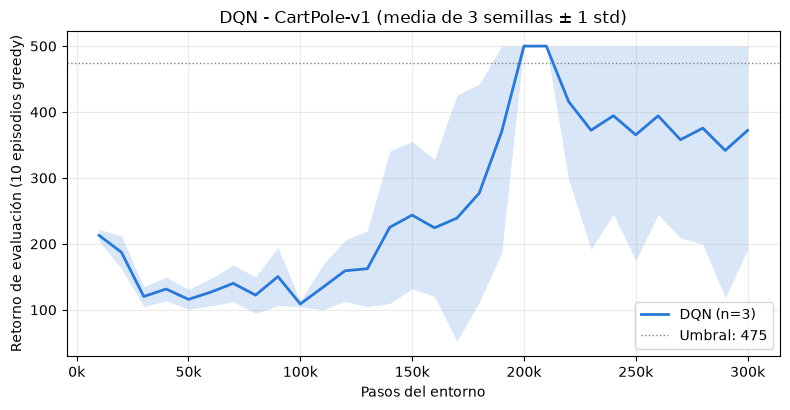

In [11]:
# ============================================================
# PART 9 - RESULTADOS DE DQN
# ============================================================

finales_dqn = cargar_finales("cartpole_dqn")
if finales_dqn.empty:
    # Respaldo: valores registrados si no está la carpeta results/
    finales_dqn = pd.DataFrame({"semilla": SEMILLAS, "media": [108.5, 500.0, 500.0],
                                "std": [27.2, 0.0, 0.0], "resuelto": [False, True, True],
                                "pasos_umbral": [190_000, 200_000, 170_000]})
print(finales_dqn.round(2).to_string(index=False))
print(f"\nMedia entre semillas: {finales_dqn['media'].mean():.2f} "
      f"± {finales_dqn['media'].std(ddof=0):.2f} | "
      f"semillas >= 475: {int(finales_dqn['resuelto'].sum())}/3")

graficar(["cartpole_dqn"], ["DQN"], umbral=475, clip=500,
         titulo="DQN - CartPole-v1 (media de 3 semillas ± 1 std)")

### Part 10 - Seed-by-Seed Diagnosis
**¿Por qué una semilla falló?** Graficamos cada semilla por separado. La semilla 42 llegó a 500 y después **olvidó** lo aprendido (olvido catastrófico): cuando el agente ya equilibra bien, el buffer se llena de estados con el poste casi vertical, desaparecen los ejemplos de fallo, y como la red comparte pesos entre todos los estados, deja de saber cómo recuperarse.

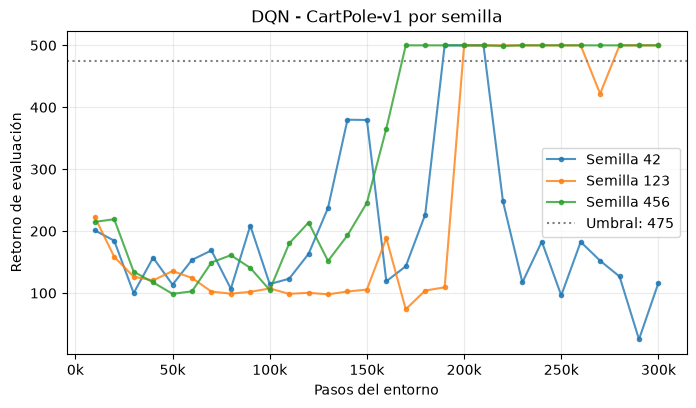

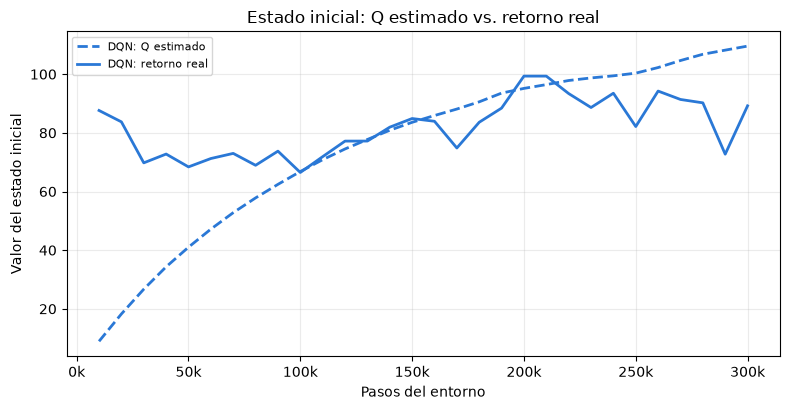

Máximo teórico con gamma = 0.99: 1 / (1 - 0.99) = 100


In [12]:
# ============================================================
# PART 10 - CURVA DE CADA SEMILLA
# ============================================================

x, Y = cargar_curvas("cartpole_dqn")
if x is not None:
    fig, ax = plt.subplots(figsize=(8, 4.2))
    for fila, s in zip(Y, SEMILLAS):
        ax.plot(x, fila, marker="o", ms=3, alpha=0.8, label=f"Semilla {s}")
    ax.axhline(475, color="gray", ls=":", label="Umbral: 475")
    ax.set_xlabel("Pasos del entorno")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
    ax.set_ylabel("Retorno de evaluación")
    ax.set_title("DQN - CartPole-v1 por semilla")
    ax.grid(alpha=0.25)
    ax.legend()
    plt.show()

graficar_sobreestimacion(["cartpole_dqn"], ["DQN"],
                         titulo="Estado inicial: Q estimado vs. retorno real")
print("Máximo teórico con gamma = 0.99: 1 / (1 - 0.99) = 100")

### Part 11 - Comparison With Q-Learning
**¿Qué método funcionó mejor?** Mismo entorno, mismos 300.000 pasos, mismas semillas y misma evaluación. Los resultados de Q-learning están en `results/cartpole_qlearning/`.

método,Q-learning,DQN
media entre semillas,493.88,369.51
std entre semillas,5.14,184.54
por semilla (42/123/456),499.0 / 486.8 / 495.8,108.5 / 500.0 / 500.0
resueltas,3/3,2/3
pasos al umbral,190k / 140k / 150k,190k / 200k / 170k
tiempo (min),0.5,7.4


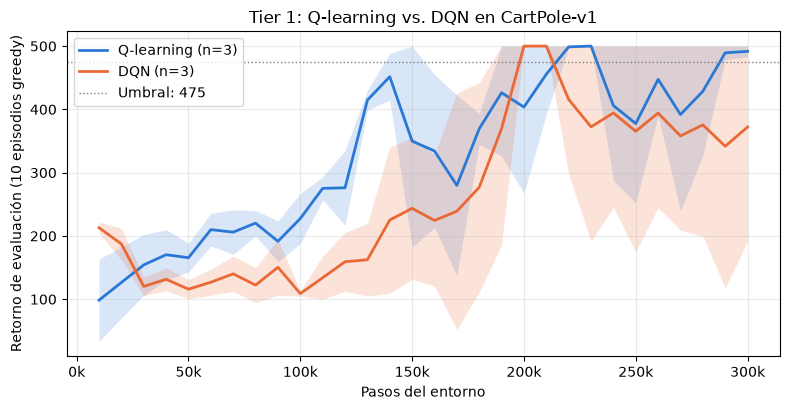

In [13]:
# ============================================================
# PART 11 - Q-LEARNING VS DQN
# ============================================================

tabla = [r for r in [resumen("cartpole_qlearning", "Q-learning"),
                     resumen("cartpole_dqn", "DQN")] if r is not None]
if tabla:
    display(pd.DataFrame(tabla).set_index("método").T)

graficar(["cartpole_qlearning", "cartpole_dqn"], ["Q-learning", "DQN"], umbral=475, clip=500,
         titulo="Tier 1: Q-learning vs. DQN en CartPole-v1")

### Part 12 - Conclusions

| Elemento | Q-learning | DQN |
|---|---|---|
| Media final (100 episodios) | **493.9 ± 5.1** | 369.5 ± 184.5 |
| Semillas ≥ 475 | **3/3** | 2/3 |
| Pasos hasta el umbral | 140k–190k | 170k–200k |
| Tiempo de entrenamiento | **0.5 min** | 7.4 min |

**Conclusiones para defender:**

- En CartPole, **Q-learning fue mejor**: mayor media, mucho más estable entre semillas y unas 15 veces más rápido.
- **Por qué:** el problema es pequeño (10 bins → 10.000 estados) y en la tabla cada actualización es **local**. En DQN cada paso de gradiente cambia los valores de todos los estados a la vez.
- **DQN sí aprendió:** las 3 semillas llegaron a 500 cerca de los 200k pasos; el mejor checkpoint de cada una da 500. El problema es mantenerlo: la semilla 42 colapsó a 108.5.
- La red sobreestima el valor del estado inicial (≈109.5 cuando el máximo posible es 100); esto motiva el Tier 3 (Double DQN).
- **Matiz honesto:** Q-learning también oscila (≈280 a los 170k pasos), y sus 300.000 pasos se eligieron después de ver los resultados de estas mismas semillas.